In [66]:
'''
Clustering
-> unsupervised learning
-> only feature no target
-> uses eigen value and eigen vector for PCA
-> uses elbow method 
    ->different from elbow in k neighbours
    ->highest drop point before any stable point
'''

'\nClustering\n-> unsupervised learning\n-> only feature no target\n-> uses eigen value and eigen vector for PCA\n-> uses elbow method \n    ->different from elbow in k neighbours\n    ->highest drop point before any stable point\n'

# K Means

In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


# K Means Model
from sklearn.cluster import KMeans
# Data Preprocessing
from sklearn.preprocessing import StandardScaler, LabelEncoder
# Metrics
from sklearn.metrics import silhouette_score

In [68]:
df = pd.read_csv('D:\Data Science\Dataset\Mall_Customers.csv')
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


### Checking Outliers

<Axes: >

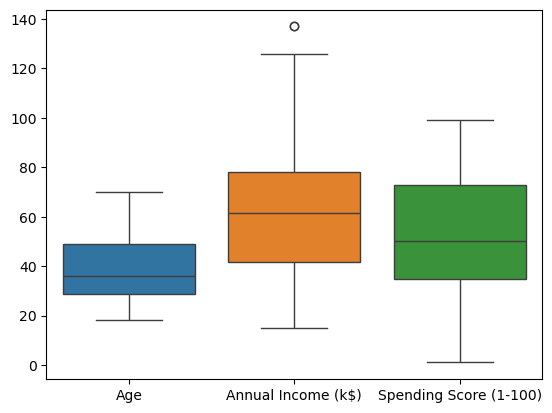

In [69]:
sns.boxplot(df[['Age','Annual Income (k$)','Spending Score (1-100)']])

In [70]:
le = LabelEncoder()

In [71]:
df['GenderID'] = le.fit_transform(df['Gender'])

In [72]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)', 'GenderID'],
      dtype='object')

## Features

In [73]:
features = [ 'Age', 'Annual Income (k$)','Spending Score (1-100)','GenderID']
X = df[features]

## Feature Scaling

In [74]:
scaler = StandardScaler()
X_scale = scaler.fit_transform(X)

## Elbow Method

In [75]:
import warnings
warnings.filterwarnings('ignore')

In [76]:
k_range = range(1,21)
error_rate =[]
for i in k_range:
    kmeans = KMeans(n_clusters=i)
    kmeans.fit_predict(X_scale)
    kmeans.inertia_
    error_rate.append(kmeans.inertia_)

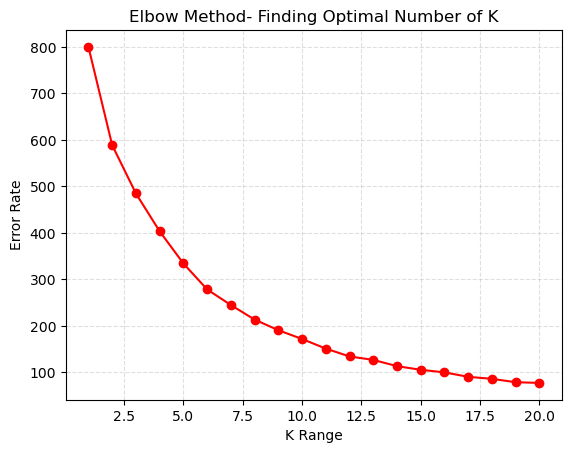

In [77]:
plt.plot(k_range, error_rate, marker = 'o', color = 'red')
plt.grid(linestyle = '--', alpha = 0.4)
plt.xlabel('K Range')
plt.ylabel('Error Rate')
plt.title('Elbow Method- Finding Optimal Number of K')
plt.show()

## Model Implementation

In [78]:
k = 5

model = KMeans(n_clusters=k)
clusters = model.fit_predict(X_scale)
clusters


array([2, 2, 3, 2, 2, 2, 1, 2, 4, 2, 4, 2, 1, 2, 4, 2, 1, 2, 4, 2, 4, 2,
       1, 2, 1, 2, 1, 2, 1, 2, 4, 2, 4, 2, 1, 2, 1, 2, 1, 2, 1, 2, 4, 2,
       1, 2, 1, 2, 2, 1, 1, 2, 2, 4, 1, 4, 1, 4, 2, 4, 4, 3, 1, 1, 4, 3,
       1, 1, 3, 1, 4, 1, 1, 1, 4, 3, 1, 4, 3, 1, 4, 4, 4, 1, 3, 4, 1, 3,
       1, 1, 1, 3, 4, 1, 1, 3, 1, 3, 4, 3, 3, 1, 4, 3, 4, 3, 1, 4, 4, 4,
       4, 3, 1, 3, 3, 3, 1, 1, 1, 1, 3, 1, 1, 0, 3, 0, 4, 0, 4, 0, 4, 0,
       3, 0, 3, 0, 1, 0, 3, 0, 1, 0, 3, 0, 3, 0, 4, 0, 1, 0, 4, 0, 1, 0,
       1, 0, 4, 0, 4, 0, 1, 0, 3, 0, 4, 0, 4, 0, 1, 0, 4, 0, 4, 0, 1, 0,
       4, 0, 4, 0, 1, 0, 4, 0, 1, 0, 1, 0, 1, 0, 1, 0, 3, 0, 1, 0, 1, 0,
       3, 0])

In [79]:
X['clusters'] = clusters

### Silhouette Score

In [80]:
ss = silhouette_score(X_scale, labels=clusters)
ss

0.301290793178201

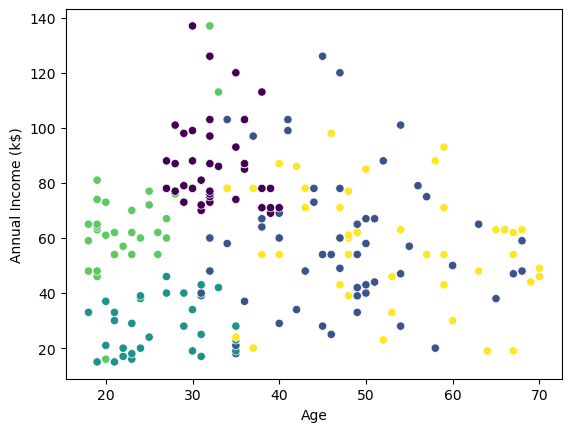

In [81]:
sns.scatterplot(data=X, x='Age', y='Annual Income (k$)', c= clusters)
plt.show()

In [82]:
px.scatter_3d(
    X,
    x='Age',
    y='Annual Income (k$)',
    z='Spending Score (1-100)',
    color = clusters
)

# Pair plot
    -option if dont want to perform PCA

In [83]:
pair_plot  = X

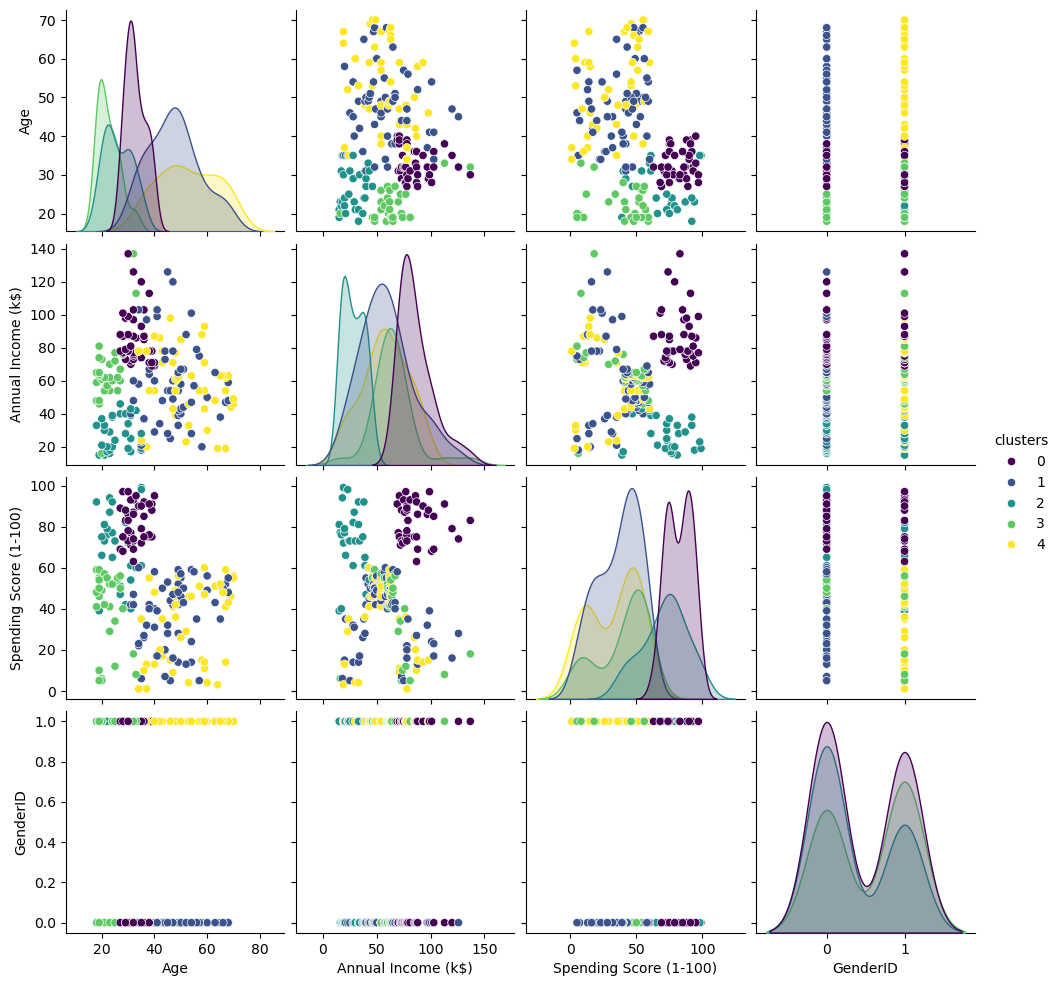

In [88]:
sns.pairplot(
    pair_plot,
    hue= 'clusters',
    palette='viridis'
)
plt.show()

## PCA (Principle Component Analysis)

In [85]:
from sklearn.decomposition import PCA